<a href="https://colab.research.google.com/github/BrownParticleAstro/dmtools_notebooks/blob/main/notebook_20261027_plot_operations_changes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Use the API client to get data

In [1]:
!pip install -i https://test.pypi.org/simple/ dmtools-brown-edu --upgrade

Looking in indexes: https://test.pypi.org/simple/


In [2]:
import json
from dmtools_brown_edu.dmtools_client_package.dmtools_quart import APIClient

In [3]:
from google.colab import userdata
api_key = userdata.get('DM_TOOLS')
email = userdata.get("DM_TOOLS_EMAIL")

In [4]:
Client = APIClient(email, api_key, suppress_logs=False)

In [5]:
# data_ids = [19176, 19177]
# colors = ["yellow", "green"]
data_ids = [19176]
colors = ["yellow"]
# styles = ["fill", "fill"]
styles = ["fill"]
display_list = []
for id in range(len(data_ids)):
  data = Client.read(id=data_ids[id])
  display = {
    "record": {
        "id": None,
        "type": "Display",
        "created": None,
        "updated": None,
        "archived": None
    },
    "properties": {
        "color": colors[id],
        "style": styles[id]
    },
    "data": data
  }
  display_list.append(display)

2026-10-27 12:01:28,574 - dmtools_brown_edu.dmtools_client_package.dmtools_quart - INFO - Calling read data API
INFO:dmtools_brown_edu.dmtools_client_package.dmtools_quart:Calling read data API
/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'app.dmtools.brown.edu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


In [29]:
display_list

[{'record': {'id': None,
   'type': 'Display',
   'created': None,
   'updated': None,
   'archived': None},
  'properties': {'color': 'yellow', 'style': 'fill'},
  'data': [{'properties': {'comment': 'LZ 2025 2 sigma',
     'dateAnnouncement': '2025-07-01',
     'dateEnd': None,
     'dateOfficial': None,
     'dateStart': None,
     'defaultColor': 'blue',
     'defaultStyle': 'line',
     'experiment': 'LUX-ZEPLIN',
     'greatestHit': 0,
     'label': 'LZ 01 Jul 2025 WS2024 2 sigma',
     'label_short': 'LZ 1 Jul 2024 2 sigma',
     'measurementType': 'Dir',
     'official': 1,
     'open': 0,
     'public': 0,
     'rating': 80,
     'raw': '{[9 6.05e-47;\n11 1.47e-47;\n13 6.35e-48;\n16 2.94e-48;\n17 2.37e-48;\n19 1.96e-48;\n21 1.64e-48;\n23 1.39e-48;\n26 1.29e-48;\n29 1.14e-48;\n32 1.08e-48;\n36 1.04e-48;\n40 1.03e-48;\n43 1.09e-48;\n46 1.06e-48;\n65 1.22e-48;\n91 1.49e-48;\n129 1.91e-48;\n182 2.55e-48;\n256 3.50e-48;\n361 5.16e-48;\n508 7.09e-48;\n1008 1.38e-47;\n2000 2.73e-47;\

### Get the new plot library

In [6]:
from google.colab import userdata
import subprocess
import base64
import os
import shutil

token = userdata.get("github_token")
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()

# Remove the directory if it already exists to avoid git clone conflict
if os.path.exists("/content/dmtools"):
    shutil.rmtree("/content/dmtools")

subprocess.run([
    "git",
    "-c", f"http.extraHeader=Authorization: Basic {auth}",
    "clone",
    "--branch", "plot_rework",
    "--single-branch",
    "https://github.com/BrownParticleAstro/dmtools.git",
    "/content/dmtools"
], check=True)

In [7]:
import sys
sys.path.insert(0, "/content/dmtools/basecode/main")

In [17]:
# @title
%pip install -r /content/dmtools/basecode/main/requirements.txt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 84.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 70.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 37.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 46.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 39.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 33.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 560.6/560.6 kB 13.7 MB/s  0:00:00
  Created wheel for Quart-Session: filename=quart_session-3.0.0-py2.py3-none-any.whl size=15859 sha256=7d8108bac53b53c903fdb1ecd5ba46127940777666fad7c8d2f5b7c9121fa2ac
  Stored in directory: /root/.cache/pip/wheels/46/8d/86/bf1c5a0f084ec32bfb6442133fd3eca2d7299a6aa8e

In [18]:
from app.libraries.plot_operations.v1.plot_operations import render_plot_from_data_original

/content/dmtools/basecode/main/app/libraries/shared_operations/v0/search_string.py:221: SyntaxWarning: invalid escape sequence '\w'
  key_value_pairs = re.findall(r"(\w+):([^\s]+)", user_query)


### Use the new context agnostic plot library to generate a plot using the data from above

In [19]:
# We import the module again to ensure the changes to plot_operations.py are reloaded
import importlib
import app.libraries.plot_operations.v1.plot_operations
importlib.reload(app.libraries.plot_operations.v1.plot_operations)
from app.libraries.plot_operations.v1.plot_operations import render_plot_from_data_original

plot_id = -1
plot_properties = {'id' : -1, 'name': 'Will test plot', 'xMax': '10000', 'xMin': '10', 'yMax': '-44', 'yMin': '-49', 'no_id': 1, 'xUnits': 'GeV/c^2', 'yUnits': 'cm2'}
display_data_list = display_list
output_format = "notebook"

In [20]:
plot_dict = {
        "plot_node": {"record": {"id": 1}, "properties": plot_properties},
        "display_data": display_data_list
    }

In [26]:
# ============================================================================
# COLAB ADAPTER: Standalone usage in notebooks
# ============================================================================

import io
import base64
from typing import Dict, List, Optional, Tuple, Any
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import LogFormatterMathtext
import numpy as np

async def plot_from_dict(plot_dict: Dict[str, Any]) -> None:
    plot_properties = plot_dict.get("plot_node", {}).get("properties", {})
    display_data_list = plot_dict.get("display_data", [])

    plot_name, fig = await render_plot_from_data_original(
        plot_data=plot_dict,
        plot_properties=plot_properties,
        display_data_list=display_data_list,
        output_format="object"
    )

    plt.show()



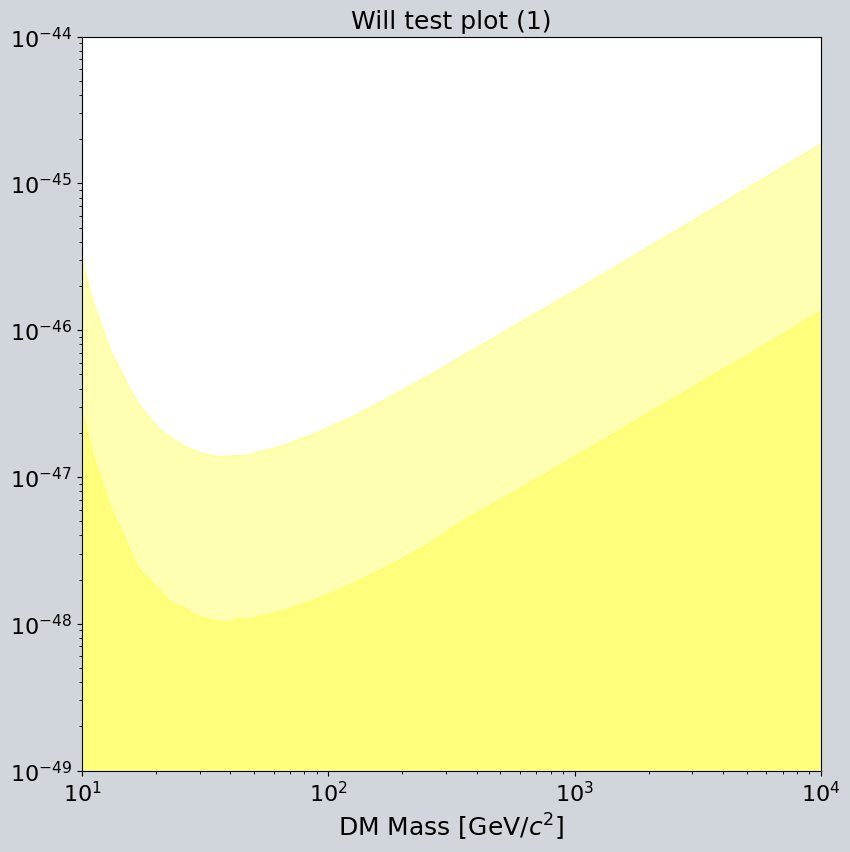

In [27]:
await plot_from_dict(plot_dict)